# MM/GBSA（单轨迹）批量分析

配套：`analysis_agent.py`（结构指标）、`mmpbsa_agent.py`（本 notebook 的执行器）

## 这个 notebook 回答什么

在**已经稳定的结合姿态**上，比较不同变体与配体的**相互作用自由能**相对差（ΔΔG）。

## 三条必须记住的边界

1. **ΔEEL 与 ΔEGB 必须成对出现**。带电界面下两者大幅抵消（本项目实测 WT: ΔEEL −51 / ΔEGB +60）；
   单独引用 ΔEEL 会得出"结合强了 90 kcal/mol"这种荒谬结论。
2. **单轨迹 + 隐式溶剂 + 无熵项** → 只报 **ΔΔG 的方向与量级**，不报绝对 ΔG。
   本方法的典型噪声 ±3–5 kcal/mol，小于此的差异不可解释。
3. **"都保持结合的两条轨迹"给出相近的 ΔG 是正常现象**，不代表亲和力相同。
   ITC 的"不结合"往往来自熵/构象选择/到达位点的动力学，普通 MD + MM/GBSA 看不到。

In [1]:
import os, subprocess, sys
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ===================== CONFIG =====================
BASE     = "/root/autodl-tmp/GROMACS"
VARIANTS = ["WT", "Y262A", "S261E"]
REF      = "WT"
WINDOW   = (50, 100)      # 只取平衡后的 50–100 ns
FRAMES   = 125            # 抽取帧数
METHOD   = "gb"           # gb -> igb=5；pb -> PB 求解（慢 ~10 倍）
SALT     = 0.15
REUSE    = True           # True: 已有 .dat 就只汇总
AGENT    = f"{BASE}/ANALYSIS/scripts/mmpbsa_agent.py"
# =================================================

print("agent:", AGENT, os.path.exists(AGENT))
print("variants:", VARIANTS, "| ref:", REF, "| window:", WINDOW, "ns |", FRAMES, "frames")

agent: /root/autodl-tmp/GROMACS/ANALYSIS/scripts/mmpbsa_agent.py True
variants: ['WT', 'Y262A', 'S261E'] | ref: WT | window: (50, 100) ns | 125 frames


## 为什么先要做 "dry tpr + nojump"

直接把带水的 `md.tpr` 丢给 gmx_MMPBSA 有两个坑：

1. **水/离子被包含** → 计算慢 10 倍，还容易在能量输出里溢出成 `*******`；
2. **周期性跳变** → 配体在某些帧被成像到盒子另一侧，ΔG 变成 ≈0（本项目实测 6 帧里有 2 帧如此）。

正确做法（`mmpbsa_agent.py` 的 `prep()` 已实现）：

```bash
# 1) 只保留 蛋白 + 配体
gmx select -s md.tpr -select 'group "Protein" or group "PEB"' -on dry.ndx
gmx convert-tpr -s md.tpr -n dry.ndx -o dry.tpr
# 2) 先 nojump 再 mol+center（顺序不能反）
gmx trjconv -s md.tpr -f md_<V>.xtc -n dry.ndx -o tmp.xtc -pbc nojump -b 50000 -e 100000 -dt 200
gmx trjconv -s md.tpr -f tmp.xtc -n dry.ndx -o dry.xtc -pbc mol -center -ur compact
```

In [2]:
cmd = [sys.executable, "-u", AGENT] + VARIANTS + ["--ref", REF,
       "--window", str(WINDOW[0]), str(WINDOW[1]),
       "--frames", str(FRAMES), "--method", METHOD, "--salt", str(SALT)]
if REUSE:
    cmd.append("--reuse")
print(" ".join(cmd))
r = subprocess.run(cmd, text=True, capture_output=True)
print(r.stdout[-3000:])
print(r.stderr[-600:] if r.returncode else "")

/root/autodl-tmp/miniconda3/bin/python -u /root/autodl-tmp/GROMACS/ANALYSIS/scripts/mmpbsa_agent.py WT Y262A S261E --ref WT --window 50 100 --frames 125 --method gb --salt 0.15 --reuse



=== ΔG_bind（GB, kcal/mol, n 帧）===
WT       ΔG =  -40.28 ± 1.45 (SEM, n=125)   [VDW -43.6 | EEL -50.7 | 60.0 | ESURF -6.0]
Y262A    ΔG =  -42.34 ± 0.48 (SEM, n=125)   [VDW -47.7 | EEL -54.4 | 66.4 | ESURF -6.6]
S261E    ΔG =  -50.58 ± 0.87 (SEM, n=125)   [VDW -46.9 | EEL -141.3 | 144.4 | ESURF -6.8]

=== ΔΔG vs WT（正值 = 结合变弱）===
Y262A    ΔΔG =  -2.06 ± 1.52 kcal/mol
S261E    ΔΔG = -10.30 ± 1.69 kcal/mol
[11:14:32] summary -> /root/autodl-tmp/GROMACS/ANALYSIS/mmpbsa_summary.csv
[11:14:33] figure -> /root/autodl-tmp/GROMACS/ANALYSIS/mmpbsa_bar.png




variant  dG_kcal   sem  n_frames  dDG_vs_WT  dDG_err
     WT  -40.280 1.446       125      0.000    2.044
  Y262A  -42.339 0.479       125     -2.059    1.523
  S261E  -50.582 0.874       125    -10.301    1.689


figure -> /root/autodl-tmp/GROMACS/ANALYSIS/mmpbsa_bar.png


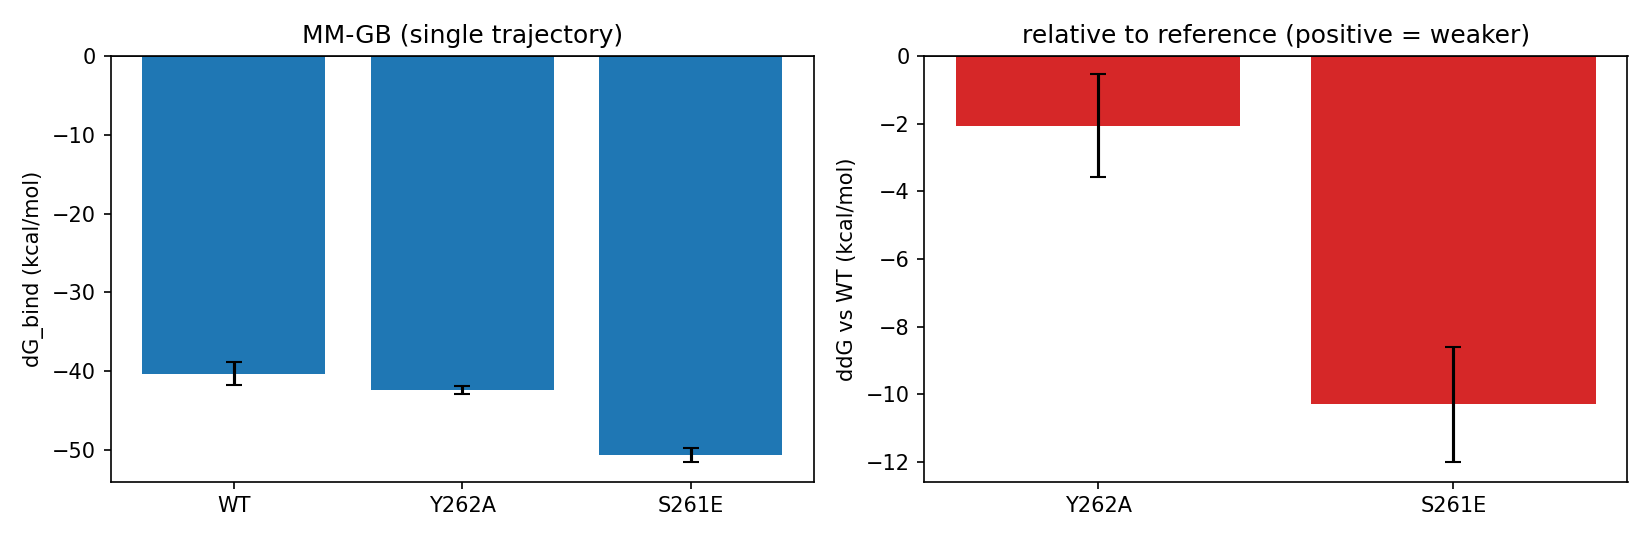

In [3]:
csv = f"{BASE}/ANALYSIS/mmpbsa_summary.csv"
df = pd.read_csv(csv)
print(df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
# 注意：df.sem / df.variant 会命中 pandas 的同名方法，必须用 df["..."] 取值
ax[0].bar(df["variant"], df["dG_kcal"], yerr=df["sem"], capsize=4, color="C0")
ax[0].set(ylabel="dG_bind (kcal/mol)", title="MM-%s (single trajectory)" % METHOD.upper())
ax[0].axhline(0, c="k", lw=.8)

sub = df[df["variant"] != REF]
ddg_col = [c for c in df.columns if c.startswith("dDG")][0]
err_col = "dDG_err" if "dDG_err" in df.columns else ddg_col + "_err"
ax[1].bar(sub["variant"], sub[ddg_col], yerr=sub[err_col], capsize=4, color="C3")
ax[1].axhline(0, c="k", lw=.8)
ax[1].set(ylabel="ddG vs %s (kcal/mol)" % REF, title="relative to reference (positive = weaker)")
plt.tight_layout()
png = f"{BASE}/ANALYSIS/mmpbsa_bar.png"
plt.savefig(png, dpi=150)
print("figure ->", png)
from IPython.display import Image, display
display(Image(png))

## 结果怎么读

| 观察 | 含义 | 怎么写进报告 |
|---|---|---|
| |ΔΔG| < 3 kcal/mol | 在噪声内 | "两者在结合姿态下相互作用能相当" |
| ΔΔG > +3 | 结合变弱 | 与 ITC 的亲和力下降方向一致可互相印证 |
| ΔΔG < −3 | 该突变**增强**了结合姿态下的相互作用 | 需检查是否换了结合模式（看接触图/取向） |
| 某变体 ΔEEL/ΔEGB 异常大（近 3 倍） | 落位方式变了 | 这种情况 ΔΔG 不能当"亲和力"解读 |

**不能写**："ΔG = −40 kcal/mol 所以 Kd = ..."。单轨迹 MM/GBSA 的绝对值没有物理意义，只能比。

## 想要与 ITC 可比的数值？

- **伞形采样 PMF**：沿配体–蛋白质心拉开到 3 nm → 得到 ΔG_off
- **Alchemical FEP**：ΔΔG_bind（需两态皆稳定采样）
- 两者都比亚马逊式的"再换一个介电常数"靠谱得多